In [1]:
import pandas as pd
import sys
import numpy as np
import seaborn as sns
sns.set_style("white")
sns.set_style("ticks")
import matplotlib.pyplot as plt
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
import os
from scipy import stats
import math
from Bio import SeqIO
from statsmodels.stats.multitest import multipletests
import upsetplot as upset
import matplotlib as mpl

In [2]:
# function to compute proportions of intron positions
def prop_intron_position(IR, intron_count, df) :
    return(intron_count / df[df['dir'] == IR]['intron_count'].sum())

In [3]:
# correlation splicing replicates
fraction_spliced_shCTL_nuc_rep1 = pd.read_table('Fig3/splicing_fraction_spliced/shCTL_nucleus_rep1_fraction_spliced.txt', index_col=[0], dtype={'chrom':'str'})
fraction_spliced_shCTL_nuc_rep2 = pd.read_table('Fig3/splicing_fraction_spliced/shCTL_nucleus_rep2_fraction_spliced.txt', index_col=[0], dtype={'chrom':'str'})
fraction_spliced_shCTL_nuc_rep3 = pd.read_table('Fig3/splicing_fraction_spliced/shCTL_nucleus_rep3_fraction_spliced.txt', index_col=[0], dtype={'chrom':'str'})

fraction_spliced_shPABPN1_nuc_rep1 = pd.read_table('Fig3/splicing_fraction_spliced/shPABPN1_nucleus_rep1_fraction_spliced.txt', index_col=[0], dtype={'chrom':'str'})
fraction_spliced_shPABPN1_nuc_rep2 = pd.read_table('Fig3/splicing_fraction_spliced/shPABPN1_nucleus_rep2_fraction_spliced.txt', index_col=[0], dtype={'chrom':'str'})
fraction_spliced_shPABPN1_nuc_rep3 = pd.read_table('Fig3/splicing_fraction_spliced/shPABPN1_nucleus_rep3_fraction_spliced.txt', index_col=[0], dtype={'chrom':'str'})

fraction_spliced_shCTL_cyto_rep1 = pd.read_table('Fig3/splicing_fraction_spliced/shCTL_cyto_rep1_fraction_spliced.txt', index_col=[0], dtype={'chrom':'str'})
fraction_spliced_shCTL_cyto_rep2 = pd.read_table('Fig3/splicing_fraction_spliced/shCTL_cyto_rep2_fraction_spliced.txt', index_col=[0], dtype={'chrom':'str'})
fraction_spliced_shCTL_cyto_rep3 = pd.read_table('Fig3/splicing_fraction_spliced/shCTL_cyto_rep3_fraction_spliced.txt', index_col=[0], dtype={'chrom':'str'})

fraction_spliced_shPABPN1_cyto_rep1 = pd.read_table('Fig3/splicing_fraction_spliced/shPABPN1_cyto_rep1_fraction_spliced.txt', index_col=[0], dtype={'chrom':'str'})
fraction_spliced_shPABPN1_cyto_rep2 = pd.read_table('Fig3/splicing_fraction_spliced/shPABPN1_cyto_rep2_fraction_spliced.txt', index_col=[0], dtype={'chrom':'str'})
fraction_spliced_shPABPN1_cyto_rep3 = pd.read_table('Fig3/splicing_fraction_spliced/shPABPN1_cyto_rep3_fraction_spliced.txt', index_col=[0], dtype={'chrom':'str'})

fraction_spliced_shCTL_nuc_rep1.head()

,chrom,intron_start,intron_end,strand,gene_name,intron_count,NO,YES,fraction_spliced
0,1,926013,930154,+,NM_152486.2,1,4.0,15.0,0.789474
1,1,930336,931038,+,NM_152486.2,2,1.0,19.0,0.950000
2,1,931089,935771,+,NM_152486.2,3,2.0,17.0,0.894737
3,1,935896,939039,+,NM_152486.2,4,1.0,27.0,0.964286
4,1,939129,939274,+,NM_152486.2,5,0.0,29.0,1.000000


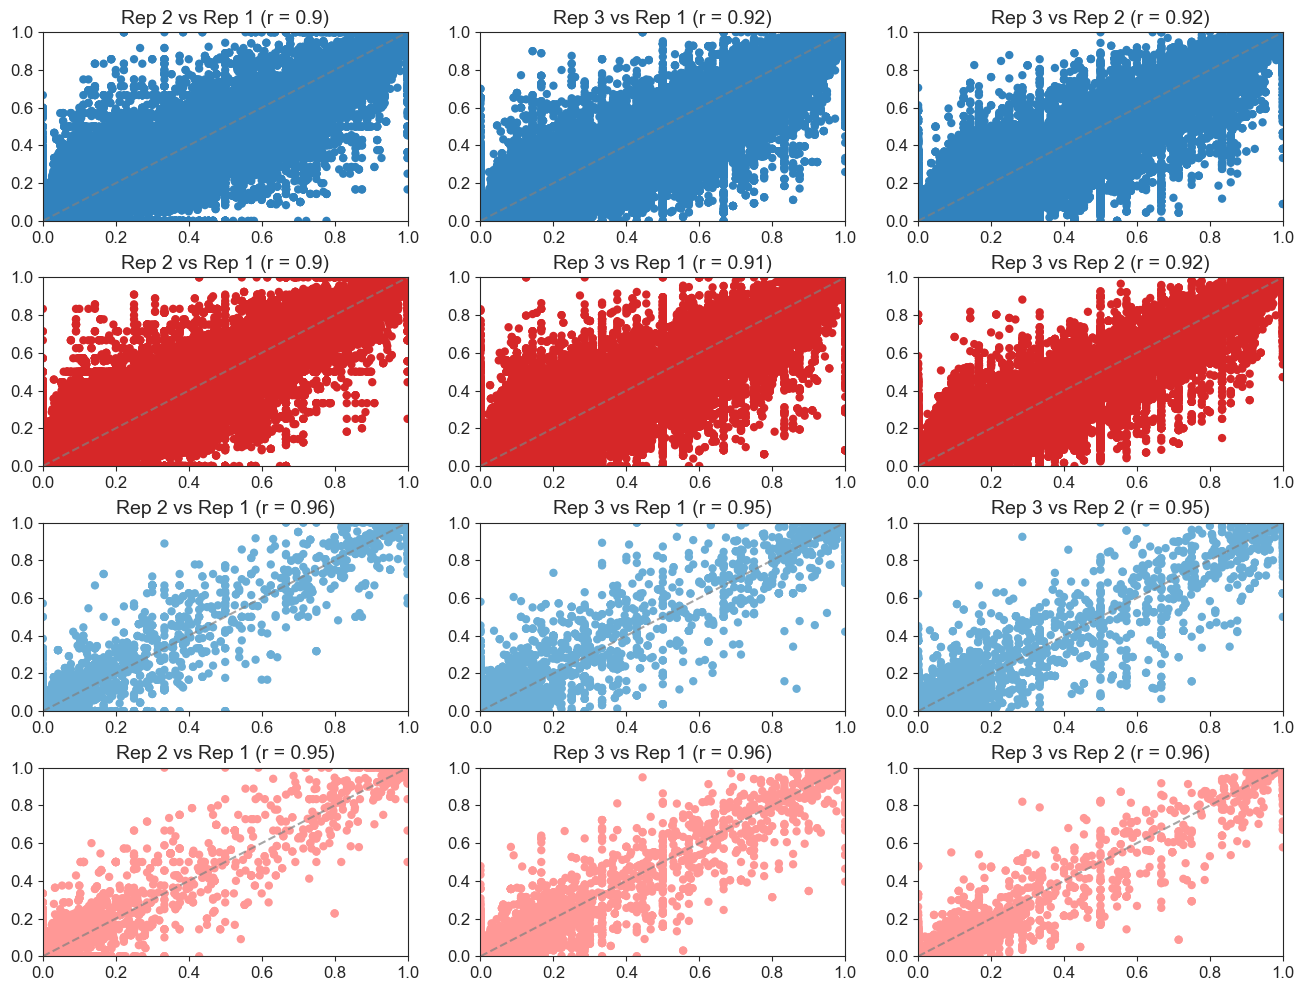

In [4]:
shCTL_nucleus_list_df = [fraction_spliced_shCTL_nuc_rep1, fraction_spliced_shCTL_nuc_rep2, fraction_spliced_shCTL_nuc_rep3]
shPABPN1_nucleus_list_df = [fraction_spliced_shPABPN1_nuc_rep1, fraction_spliced_shPABPN1_nuc_rep2, fraction_spliced_shPABPN1_nuc_rep3]
shCTL_cyto_list_df = [fraction_spliced_shCTL_cyto_rep1, fraction_spliced_shCTL_cyto_rep2, fraction_spliced_shCTL_cyto_rep3]
shPABPN1_cyto_list_df = [fraction_spliced_shPABPN1_cyto_rep1, fraction_spliced_shPABPN1_cyto_rep2, fraction_spliced_shPABPN1_cyto_rep3]


custom_palette = [sns.color_palette('tab20c')[0], sns.color_palette('tab20')[6], sns.color_palette('tab20c')[1], sns.color_palette('tab20')[7]]
fig, axes = plt.subplots(4, 3, figsize=(16, 12))
list_all_df = [shCTL_nucleus_list_df, shPABPN1_nucleus_list_df, shCTL_cyto_list_df, shPABPN1_cyto_list_df]
list_titles = ['Rep 2 vs Rep 1', 'Rep 3 vs Rep 1', 'Rep 3 vs Rep 2']
for i in range(4) :
    df_list = list_all_df[i]
    merge_df_rep1_rep2 = df_list[0].merge(df_list[1], on = ['chrom', 'intron_start', 'intron_end', 'strand', 'gene_name', 'intron_count'])
    merge_df_rep1_rep3 = df_list[0].merge(df_list[2], on = ['chrom', 'intron_start', 'intron_end', 'strand', 'gene_name', 'intron_count'])
    merge_df_rep2_rep3 = df_list[1].merge(df_list[2], on = ['chrom', 'intron_start', 'intron_end', 'strand', 'gene_name', 'intron_count'])
    list_merge = [merge_df_rep1_rep2, merge_df_rep1_rep3, merge_df_rep2_rep3]
    for j in range(3) :
        merge_df = list_merge[j]
        merge_df['IR_ratio_x'] = 1 - merge_df['fraction_spliced_x']
        merge_df['IR_ratio_y'] = 1 - merge_df['fraction_spliced_y']
        xlist = merge_df['IR_ratio_x'].tolist()
        ylist = merge_df['IR_ratio_y'].tolist()
        pvalue = stats.pearsonr(x=xlist, y=ylist)[0]
        sns.scatterplot(data = merge_df, x = 'IR_ratio_x', y = 'IR_ratio_y', ax = axes[i, j], edgecolor = 'none', color = custom_palette[i], rasterized = True)
        axes[i, j].set_xlim(0, 1)
        axes[i, j].set_ylim(0, 1)
        #axes[i, j].text(x=0.2, y=0.7, s='r = ' + str(pvalue.round(2)), fontsize=14, color='red')
        axes[i, j].set_xlabel('')
        axes[i, j].set_ylabel('')
        axes[i, j].plot((0, 1), (0, 1), color='grey', linestyle='--', alpha=0.7)
        axes[i, j].set_title(list_titles[j] + ' (r = ' + str(pvalue.round(2)) + ')', fontsize = 14)
        axes[i, j].tick_params(labelsize = 12)
plt.subplots_adjust(hspace = 0.3)

In [5]:
nucleus_introns = pd.read_table('Fig3/IR_analysis_nuc.txt', index_col=[0], dtype={'chrom' : 'str'})
nucleus_introns.loc[nucleus_introns['sig'] == 'no', 'dir'] = 'not_significant'

cyto_introns = pd.read_table('Fig3/IR_analysis_cyto.txt', index_col=[0], dtype={'chrom' : 'str'})
cyto_introns.loc[cyto_introns['sig'] == 'no', 'dir'] = 'not_significant'

nucleus_introns.head()

,chrom,intron_start,intron_end,strand,intron_count,NO_x,YES_x,NO_y,YES_y,gene_name,...,BP_score_median,BP_score_max,GC_content,pvalue,FDR,fraction_spliced_x,fraction_spliced_y,delta,dir,sig
0,1,44776774,44777613,+,2,2762.0,5246.0,1871.0,14040.0,RPS8,...,0.643993,0.643993,53.516091,0.000000e+00,0.000000e+00,0.655095,0.882408,-0.227313,less_IR_PABPN1,yes
1,1,44777789,44777999,+,3,2398.0,6309.0,1444.0,15033.0,RPS8,...,0.908487,0.908487,54.761905,1.482197e-322,3.527703e-318,0.724589,0.912363,-0.187773,less_IR_PABPN1,yes
2,22,39313729,39314106,-,2,2389.0,3702.0,1310.0,8159.0,RPL3,...,0.782526,0.782526,57.559682,1.015161e-283,1.610756e-279,0.607782,0.861654,-0.253872,less_IR_PABPN1,yes
3,22,39313310,39313633,-,1,2424.0,4236.0,1313.0,8441.0,RPL3,...,0.556392,0.556392,57.275542,2.763257e-256,3.288345e-252,0.636036,0.865389,-0.229353,less_IR_PABPN1,yes
4,22,39316841,39317460,-,6,1624.0,1849.0,1178.0,6111.0,RPL3,...,0.488048,0.488048,56.542811,7.474881e-240,7.116236e-236,0.532393,0.838387,-0.305994,less_IR_PABPN1,yes


In [6]:
# export data for volcano plots
nucleus_introns_volcano = nucleus_introns[nucleus_introns['FDR'] != 0]
nucleus_introns_volcano['log10pvalue'] = nucleus_introns_volcano.apply(lambda row : -math.log10(row.FDR), axis = 1)
nucleus_introns_volcano.to_csv('Fig3/nucleus_introns_volcano.txt', sep = '\t')

cyto_introns_volcano = cyto_introns[cyto_introns['FDR'] != 0]
cyto_introns_volcano['log10pvalue'] = cyto_introns_volcano.apply(lambda row : -math.log10(row.FDR), axis = 1)
cyto_introns_volcano.to_csv('Fig3/cyto_introns_volcano.txt', sep = '\t')

C:\Users\bacs5867\AppData\Local\Temp\ipykernel_13744\3295652679.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nucleus_introns_volcano['log10pvalue'] = nucleus_introns_volcano.apply(lambda row : -math.log10(row.FDR), axis = 1)


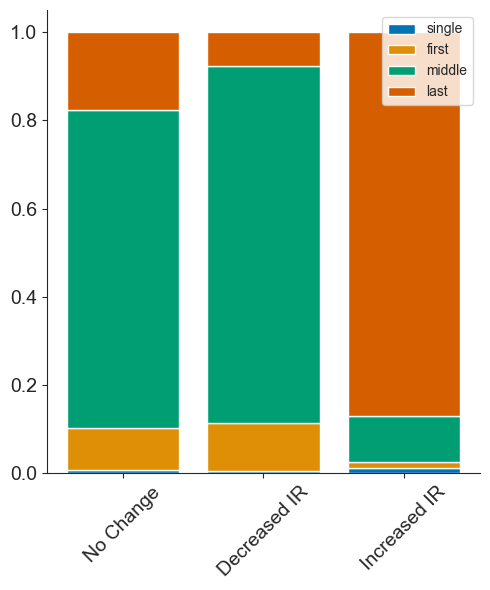

In [7]:
# barplots intron numbers
# nucleus


nucleus_introns_count = nucleus_introns.groupby(by = ['dir', 'intron_order'])['name'].count().reset_index().rename(columns = {'name' : 'intron_count'})
nucleus_introns_count['proportion'] = nucleus_introns_count.apply(lambda row : prop_intron_position(row.dir, row.intron_count, nucleus_introns_count), axis = 1)
nucleus_introns_count_piv = nucleus_introns_count.pivot_table(index = 'dir', columns = 'intron_order', values = 'proportion')
nucleus_introns_count_piv = nucleus_introns_count_piv[['single', 'first', 'middle', 'last']]
nucleus_introns_count_piv = nucleus_introns_count_piv.loc[['not_significant', 'less_IR_PABPN1', 'more_IR_PABPN1']]
nucleus_introns_count_piv.index = ['No Change', 'Decreased IR', 'Increased IR']

fig, ax = plt.subplots(figsize=(5,6))
left = np.zeros(len(nucleus_introns_count_piv))
palette = sns.color_palette('colorblind', n_colors=nucleus_introns_count_piv.shape[1])
for i, col in enumerate(nucleus_introns_count_piv.columns):
    ax.bar(nucleus_introns_count_piv.index, nucleus_introns_count_piv[col], bottom=left, label=col, color=palette[i])
    left += nucleus_introns_count_piv[col].values
ax.tick_params(labelsize=14)
ax.set_ylabel('')
ax.set_xlabel('')
ax.set_xticks([0,1,2], nucleus_introns_count_piv.index, rotation= 45)
sns.despine()
ax.legend()
plt.tight_layout()

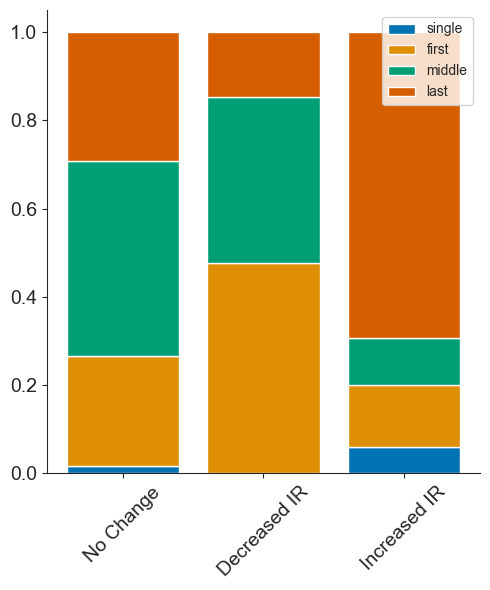

In [8]:
# cytoplasm
cyto_introns_count = cyto_introns.groupby(by = ['dir', 'intron_order'])['name'].count().reset_index().rename(columns = {'name' : 'intron_count'})
cyto_introns_count['proportion'] = cyto_introns_count.apply(lambda row : prop_intron_position(row.dir, row.intron_count, cyto_introns_count), axis = 1)
cyto_introns_count_piv = cyto_introns_count.pivot_table(index = 'dir', columns = 'intron_order', values = 'proportion').fillna(0)
cyto_introns_count_piv = cyto_introns_count_piv[['single', 'first', 'middle', 'last']]
cyto_introns_count_piv = cyto_introns_count_piv.loc[['not_significant', 'less_IR_PABPN1', 'more_IR_PABPN1']]
cyto_introns_count_piv.index = ['No Change', 'Decreased IR', 'Increased IR']


fig, ax = plt.subplots(figsize=(5,6))
left = np.zeros(len(cyto_introns_count_piv))
palette = sns.color_palette('colorblind', n_colors=cyto_introns_count_piv.shape[1])
for i, col in enumerate(cyto_introns_count_piv.columns):
    ax.bar(cyto_introns_count_piv.index, cyto_introns_count_piv[col], bottom=left, label=col, color=palette[i])
    left += cyto_introns_count_piv[col].values
#ax.set_ylim(0, 1)
#plt.title('Nucleus', fontsize = 18)
ax.tick_params(labelsize=14)
ax.set_ylabel('')
ax.set_xlabel('')
ax.set_xticks([0,1,2], cyto_introns_count_piv.index, rotation= 45)
sns.despine()
ax.legend()
plt.tight_layout()

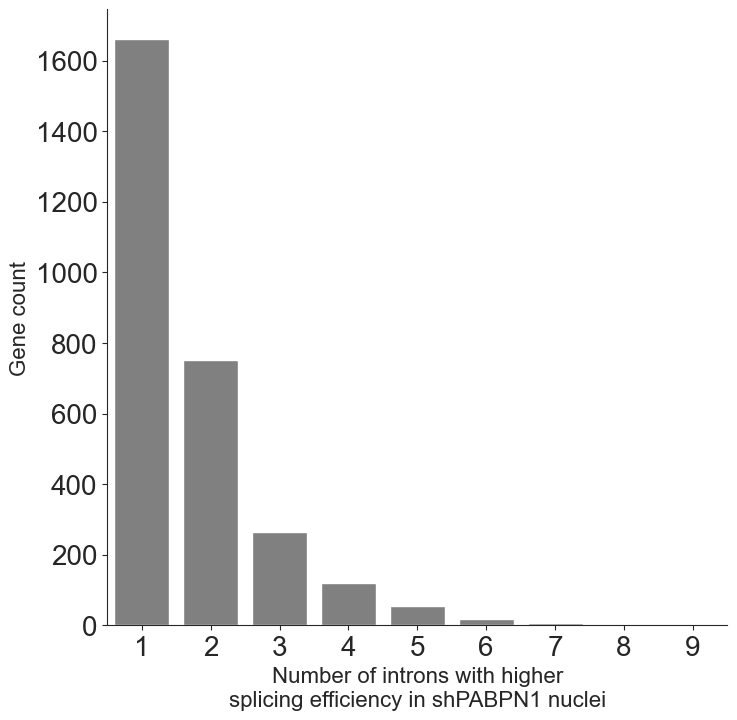

In [9]:
# number of less retained introns per gene
nucleus_introns_less_IR = nucleus_introns[nucleus_introns['dir'] == 'less_IR_PABPN1']
nucleus_introns_less_IR_count = nucleus_introns_less_IR.groupby(by = 'gene_name')['name'].count().reset_index()
nucleus_introns_less_IR_count_dist = nucleus_introns_less_IR_count.groupby(by = 'name')['gene_name'].count().reset_index()

fig, axes = plt.subplots(figsize=(8, 8))
sns.barplot(data = nucleus_introns_less_IR_count_dist, x = 'name', y = 'gene_name', color = 'grey')
plt.xlabel('Number of introns with higher\nsplicing efficiency in shPABPN1 nuclei', fontsize = 16)
plt.ylabel('Gene count', fontsize = 16)
plt.tick_params(labelsize = 20)
sns.despine()


# Characteristics of PABPN1-sensitive introns

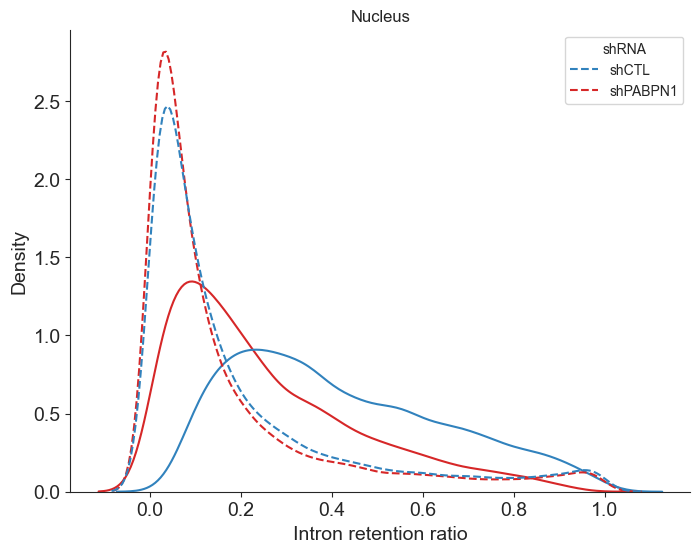

In [10]:
# IR ratio
nucleus_introns['IR_ratio_shCTL'] = 1 - nucleus_introns['fraction_spliced_x']
nucleus_introns['IR_ratio_shPABPN1'] = 1 - nucleus_introns['fraction_spliced_y']
nucleus_introns_shCTL = nucleus_introns[['name', 'intron_order', 'dir', 'IR_ratio_shCTL']].rename(columns={'IR_ratio_shCTL' : 'IR_ratio'})
nucleus_introns_shCTL['shRNA'] = 'shCTL'
nucleus_introns_shPABPN1 = nucleus_introns[['name', 'intron_order', 'dir', 'IR_ratio_shPABPN1']].rename(columns={'IR_ratio_shPABPN1' : 'IR_ratio'})
nucleus_introns_shPABPN1['shRNA'] = 'shPABPN1'
nucleus_introns_IR_ratio = pd.concat([nucleus_introns_shCTL, nucleus_introns_shPABPN1]).reset_index(drop = True)

fig, ax = plt.subplots(figsize=(8,6))
sns.kdeplot(data = nucleus_introns_IR_ratio[nucleus_introns_IR_ratio['dir'] == 'less_IR_PABPN1'], x = 'IR_ratio', hue = 'shRNA', palette=[sns.color_palette('tab20c')[0], sns.color_palette('tab20')[6]])
sns.kdeplot(data = nucleus_introns_IR_ratio[nucleus_introns_IR_ratio['dir'] == 'not_significant'], x = 'IR_ratio', hue = 'shRNA', palette=[sns.color_palette('tab20c')[0], sns.color_palette('tab20')[6]], linestyle = '--')
plt.ylabel('Density', fontsize = 14)
plt.xlabel('Intron retention ratio', fontsize = 14)
plt.tick_params(labelsize = 14)
plt.title('Nucleus')
sns.despine()

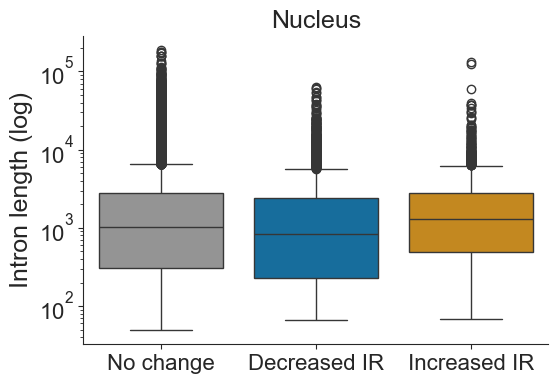

In [11]:
# intron length
custom_palette = [sns.color_palette('colorblind')[0], sns.color_palette('colorblind')[1], sns.color_palette('colorblind')[7]]
fig, ax = plt.subplots(figsize=(6,4))
sns.boxplot(data = nucleus_introns, x = 'dir', y = 'intron_length', order = ['not_significant', 'less_IR_PABPN1', 'more_IR_PABPN1'], hue = 'dir', palette = custom_palette)
plt.yscale('log')
plt.ylabel('Intron length (log)', fontsize = 18)
plt.xlabel('')
plt.xticks(ticks= [0,1,2], labels = ['No change', 'Decreased IR', 'Increased IR'])
plt.tick_params(labelsize = 16)
plt.title('Nucleus', fontsize = 18)
sns.despine()

In [12]:
# stat test intron length
list_length_nosig = nucleus_introns[nucleus_introns['dir'] == 'not_significant']['intron_length'].tolist()
list_length_less_IR = nucleus_introns[nucleus_introns['dir'] == 'less_IR_PABPN1']['intron_length'].tolist()
list_length_more_IR = nucleus_introns[nucleus_introns['dir'] == 'more_IR_PABPN1']['intron_length'].tolist()
pvalue_less_IR = stats.mannwhitneyu(x = list_length_nosig, y = list_length_less_IR)[1]
pvalue_more_IR = stats.mannwhitneyu(x = list_length_nosig, y = list_length_more_IR)[1]
print('pvalue less IR = ' + str(pvalue_less_IR))
print('pvalue more IR = ' + str(pvalue_more_IR))

pvalue less IR = 4.789272639657922e-19
pvalue more IR = 7.56557689764893e-07


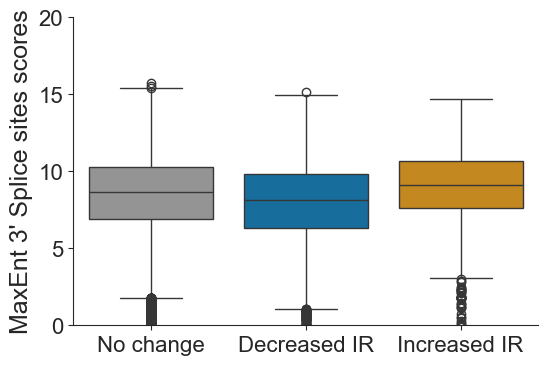

In [13]:
custom_palette = [sns.color_palette('colorblind')[0], sns.color_palette('colorblind')[1], sns.color_palette('colorblind')[7]]
fig, ax = plt.subplots(figsize=(6,4))
sns.boxplot(data = nucleus_introns, x = 'dir', y = 'MaxEnt_score_3SS', order = ['not_significant', 'less_IR_PABPN1', 'more_IR_PABPN1'], hue = 'dir', palette=custom_palette)
plt.ylim(0,20)
plt.ylabel("MaxEnt 3' Splice sites scores", fontsize = 18)
plt.xlabel('')
plt.xticks(ticks= [0,1,2], labels = ['No change', 'Decreased IR', 'Increased IR'])
plt.tick_params(labelsize = 16)
#plt.title('shCTL Nucleus', fontsize = 16)
sns.despine()

In [14]:
# stat test 3'SS MaxEnt score
list_3SS_nosig = nucleus_introns[nucleus_introns['dir'] == 'not_significant']['MaxEnt_score_3SS'].tolist()
list_3SS_less_IR = nucleus_introns[nucleus_introns['dir'] == 'less_IR_PABPN1']['MaxEnt_score_3SS'].tolist()
list_3SS_more_IR = nucleus_introns[nucleus_introns['dir'] == 'more_IR_PABPN1']['MaxEnt_score_3SS'].tolist()
pvalue_less_IR = stats.mannwhitneyu(x = list_3SS_nosig, y = list_3SS_less_IR)[1]
pvalue_more_IR = stats.mannwhitneyu(x = list_3SS_nosig, y = list_3SS_more_IR)[1]
print('pvalue less IR = ' + str(pvalue_less_IR))
print('pvalue more IR = ' + str(pvalue_more_IR))

pvalue less IR = 8.282852898844926e-40
pvalue more IR = 2.1148047997498572e-12


pvalue less IR = 1.2024637710387364e-22
pvalue more IR = 0.08480059021526978


C:\Users\bacs5867\AppData\Local\Temp\ipykernel_13744\2231728601.py:56: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


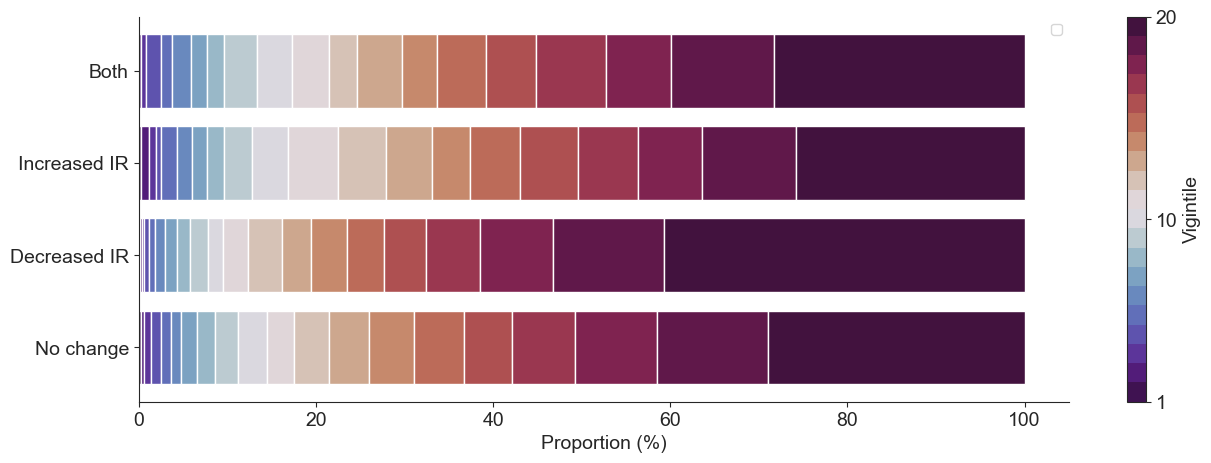

In [15]:
# TSA seq data analysis
# data from table S6 in TSA-seq article

genes_less_IR_nucleus = nucleus_introns[nucleus_introns['dir'] == 'less_IR_PABPN1']['gene_name'].drop_duplicates().tolist()
genes_more_IR_nucleus = nucleus_introns[nucleus_introns['dir'] == 'more_IR_PABPN1']['gene_name'].drop_duplicates().tolist()
genes_total_IR_nucleus = nucleus_introns['gene_name'].drop_duplicates().tolist()

def get_prop_IR_status(IR, df, count) :
    df_vig = df[df['IR_nucleus'] == IR]
    total = df_vig['gene_count'].sum()
    return((count/total) * 100)

def tsa_results(file, cell) :
    tsa_seq = pd.read_table(file).dropna()
    tsa_seq = tsa_seq[['gene_name', 'gene_id', 'gene_type', cell + '_SON_TSA_2.0', cell + '_SON_TSA_2.0.vigintiles']].rename(columns={cell + '_SON_TSA_2.0': 'tsa', cell + '_SON_TSA_2.0.vigintiles': 'vigintile'})
    tsa_seq['tsa'] = tsa_seq.apply(lambda row: float(str(row.tsa).replace(',', '.')), axis=1)
    tsa_seq['vigintile'] = tsa_seq.apply(lambda row: int(str(row.vigintile).split(' ')[1]), axis=1)
    tsa_seq['IR_nucleus'] = 'not_detected'
    tsa_seq.loc[tsa_seq['gene_name'].isin(genes_total_IR_nucleus), 'IR_nucleus'] = 'not_significant'
    tsa_seq.loc[tsa_seq['gene_name'].isin(genes_less_IR_nucleus), 'IR_nucleus'] = 'less_IR_nucleus'
    tsa_seq.loc[tsa_seq['gene_name'].isin(genes_more_IR_nucleus), 'IR_nucleus'] = 'more_IR_nucleus'
    tsa_seq.loc[(tsa_seq['gene_name'].isin(genes_more_IR_nucleus)) & (tsa_seq['gene_name'].isin(genes_less_IR_nucleus)), 'IR_nucleus'] = 'both'
    tsa_seq_count_vig = tsa_seq.groupby(by=['IR_nucleus', 'vigintile'])['gene_name'].count().reset_index().rename(columns={'gene_name': 'gene_count'})
    tsa_seq_count_vig['proportion'] = tsa_seq_count_vig.apply(lambda row: get_prop_IR_status(row.IR_nucleus, tsa_seq_count_vig, row.gene_count), axis=1)
    tsa_seq_count_vig_piv = tsa_seq_count_vig.pivot_table(index='IR_nucleus', columns='vigintile',values='proportion').fillna(0)
    order_IR = ['not_significant', 'less_IR_nucleus', 'more_IR_nucleus','both']  # removes the genes not detected == not in nucleus_introns
    tsa_seq_count_vig_piv = tsa_seq_count_vig_piv.loc[order_IR]
    tsa_seq_count_vig_piv = tsa_seq_count_vig_piv.rename(index={'not_significant': 'No change', 'less_IR_nucleus': 'Decreased IR', 'more_IR_nucleus': 'Increased IR', 'both': 'Both'})

    # stat test - enrichment in vigintile 20
    other_nochange = tsa_seq_count_vig[(tsa_seq_count_vig['IR_nucleus'] == 'not_significant') & (tsa_seq_count_vig['vigintile'] != 20)]['gene_count'].sum()
    vig20_nochange = tsa_seq_count_vig[(tsa_seq_count_vig['IR_nucleus'] == 'not_significant') & (tsa_seq_count_vig['vigintile'] == 20)]['gene_count'].sum()
    other_less_IR = tsa_seq_count_vig[(tsa_seq_count_vig['IR_nucleus'] == 'less_IR_nucleus') & (tsa_seq_count_vig['vigintile'] != 20)]['gene_count'].sum()
    vig20_less_IR = tsa_seq_count_vig[(tsa_seq_count_vig['IR_nucleus'] == 'less_IR_nucleus') & (tsa_seq_count_vig['vigintile'] == 20)]['gene_count'].sum()
    other_more_IR = tsa_seq_count_vig[(tsa_seq_count_vig['IR_nucleus'] == 'more_IR_nucleus') & (tsa_seq_count_vig['vigintile'] != 20)]['gene_count'].sum()
    vig20_more_IR = tsa_seq_count_vig[(tsa_seq_count_vig['IR_nucleus'] == 'more_IR_nucleus') & (tsa_seq_count_vig['vigintile'] == 20)]['gene_count'].sum()
    pvalue_less_IR = stats.fisher_exact([[other_nochange, vig20_nochange], [other_less_IR, vig20_less_IR]])[1]
    pvalue_more_IR = stats.fisher_exact([[other_nochange, vig20_nochange], [other_more_IR, vig20_more_IR]])[1]
    return(tsa_seq_count_vig, tsa_seq_count_vig_piv, pvalue_less_IR, pvalue_more_IR)

(tsa_seq_count_vig_h1, tsa_seq_count_vig_piv_h1, pvalue_less_IR_h1, pvalue_more_IR_h1) = tsa_results('C:/Users/bacs5867/Documents/PABPN1/tsa_seq/h1.txt', 'H1') # example for H1 cells

print('pvalue less IR = ' + str(pvalue_less_IR_h1))
print('pvalue more IR = ' + str(pvalue_more_IR_h1))

fig, ax = plt.subplots(figsize=(15,5))
left = np.zeros(len(tsa_seq_count_vig_piv_h1))
palette = sns.color_palette('twilight_shifted', n_colors=tsa_seq_count_vig_piv_h1.shape[1])
for i, col in enumerate(tsa_seq_count_vig_piv_h1.columns):
    ax.barh(tsa_seq_count_vig_piv_h1.index, tsa_seq_count_vig_piv_h1[col], left=left, color = palette[i])
    left += tsa_seq_count_vig_piv_h1[col].values
ax.tick_params(labelsize=14)
ax.set_ylabel('')
ax.set_xlabel('Proportion (%)', fontsize = 14)
sns.despine()
ax.legend()
# colorbar
cmap = mpl.colors.ListedColormap(palette)
norm = mpl.colors.Normalize(vmin=1, vmax=len(palette))
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax)
cbar.set_ticks([1, 10, len(palette)])
cbar.set_ticklabels(['1', '10', str(len(palette))])
cbar.ax.tick_params(labelsize=14)
cbar.set_label("Vigintile", fontsize = 14)


pvalue less IR = 1.6715045250098687e-22
pvalue more IR = 0.004584888315068106


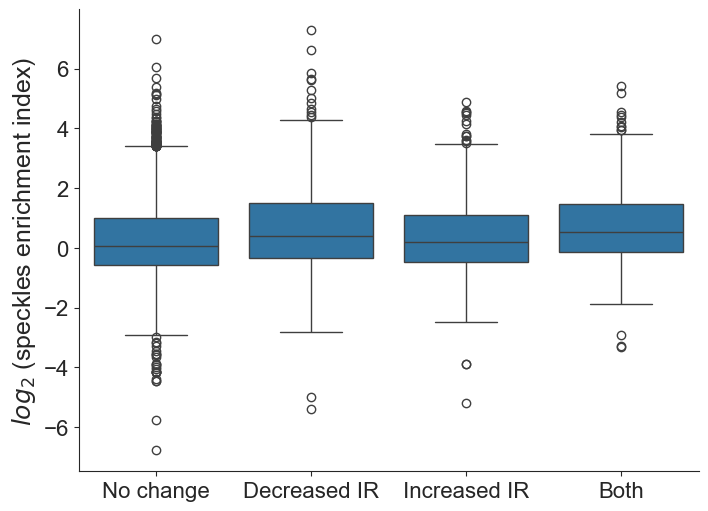

In [16]:
# ARTR Seq data analysis
# Table S3 from ARTR article

ensembl_id_hg38_114_gtf = pd.read_table('C:/Users/bacs5867/Documents/PABPN1/analyse/hg38_genome_ensembl_114/Homo_sapiens.GRCh38.114_ensembl_gene_names.txt', index_col=[0])

ARTR_Deseq2 = pd.read_table('C:/Users/bacs5867/Documents/PABPN1/ARTR_seq/DESeq2_SON_NT.txt')
ARTR_Deseq2['Geneid'] = ARTR_Deseq2.apply(lambda row: row.Geneid.split('.')[0], axis = 1)
ARTR_Deseq2 = ARTR_Deseq2.merge(ensembl_id_hg38_114_gtf, on = 'Geneid')

ARTR_Deseq2['IR_nucleus'] = 'not_detected'
ARTR_Deseq2.loc[ARTR_Deseq2['gene_name'].isin(genes_total_IR_nucleus), 'IR_nucleus'] = 'No change'
ARTR_Deseq2.loc[ARTR_Deseq2['gene_name'].isin(genes_less_IR_nucleus), 'IR_nucleus'] = 'Decreased IR'
ARTR_Deseq2.loc[ARTR_Deseq2['gene_name'].isin(genes_more_IR_nucleus), 'IR_nucleus'] = 'Increased IR'
ARTR_Deseq2.loc[(ARTR_Deseq2['gene_name'].isin(genes_less_IR_nucleus)) & (ARTR_Deseq2['gene_name'].isin(genes_more_IR_nucleus)), 'IR_nucleus'] = 'Both'
ARTR_Deseq2_count = ARTR_Deseq2.groupby(by = 'IR_nucleus')['gene_name'].count().reset_index()

# stat test
list_artr_nosig = ARTR_Deseq2[ARTR_Deseq2['IR_nucleus'] == 'No change']['log2FoldChange'].tolist()
list_artr_less_IR = ARTR_Deseq2[ARTR_Deseq2['IR_nucleus'] == 'Decreased IR']['log2FoldChange'].tolist()
list_artr_more_IR = ARTR_Deseq2[ARTR_Deseq2['IR_nucleus'] == 'Increased IR']['log2FoldChange'].tolist()
list_artr_both = ARTR_Deseq2[ARTR_Deseq2['IR_nucleus'] == 'Both']['log2FoldChange'].tolist()
pvalue_less_IR = stats.mannwhitneyu(x = list_artr_nosig, y = list_artr_less_IR)[1]
pvalue_more_IR = stats.mannwhitneyu(x = list_artr_nosig, y = list_artr_more_IR)[1]
pvalue_both = stats.mannwhitneyu(x = list_artr_nosig, y = list_artr_both)[1]

print('pvalue less IR = ' + str(pvalue_less_IR))
print('pvalue more IR = ' + str(pvalue_more_IR))

fig, ax = plt.subplots(figsize=(8,6))
sns.boxplot(data = ARTR_Deseq2[ARTR_Deseq2['IR_nucleus'] != 'not_detected'], x = 'IR_nucleus', y = 'log2FoldChange', order = ['No change', 'Decreased IR', 'Increased IR', 'Both'])
plt.ylabel(r'$log_2$' + ' (speckles enrichment index)', fontsize = 18)
plt.xlabel('')
plt.tick_params(labelsize = 16)
sns.despine()



# Intron retention in short reads data

In [17]:
# load example of IR-dir file generated by IRFinder from 1 replicate to get intron coords
irfinder_introns = pd.read_table('Fig3/IRFinder-IR-dir.txt', dtype={'Chr':'str'})
irfinder_introns['Geneid'] = irfinder_introns.apply(lambda row : row.Name.split('/')[1], axis = 1)
irfinder_introns['gene_name'] = irfinder_introns.apply(lambda row : row.Name.split('/')[0], axis = 1)
irfinder_introns['status'] = irfinder_introns.apply(lambda row : row.Name.split('/')[2], axis = 1)
irfinder_introns = irfinder_introns[['Chr', 'Start', 'End', 'Name', 'Null', 'Strand', 'Geneid', 'gene_name', 'status']]
irfinder_introns.loc[irfinder_introns['gene_name'] == '', 'gene_name'] = float('NaN')

# intron feature file to get intron order
intron_features = pd.read_table('C:/Users/bacs5867/Documents/PABPN1/analyse/hg38_all_intron_features_with_GC_and_BP_scores.txt', dtype={'chrom':'str'})[['chrom', 'start', 'end', 'strand', 'intron_order']].drop_duplicates()
intron_features.columns = ['Chr', 'Start', 'End', 'Strand', 'intron_order']

# merge
irfinder_introns = irfinder_introns.merge(intron_features, on = ['Chr', 'Start', 'End', 'Strand'], how = 'left')

irfinder_introns.head()


,Chr,Start,End,Name,Null,Strand,Geneid,gene_name,status,intron_order
0,1,924948,925921,SAMD11/ENSG00000187634/clean,0,+,ENSG00000187634,SAMD11,clean,NaN
1,1,925189,925921,SAMD11/ENSG00000187634/clean,0,+,ENSG00000187634,SAMD11,clean,NaN
2,1,925800,925921,SAMD11/ENSG00000187634/clean,0,+,ENSG00000187634,SAMD11,clean,first
3,1,926013,930154,SAMD11/ENSG00000187634/clean,0,+,ENSG00000187634,SAMD11,clean,middle
4,1,930336,931038,SAMD11/ENSG00000187634/clean,0,+,ENSG00000187634,SAMD11,clean,middle


In [18]:
shPABPN1_vs_shNT_nucleus = pd.read_table('Fig3/shPABPN1_vs_shNT_nucleus.txt', index_col=[0])
shPABPN1_vs_shNT_nucleus = shPABPN1_vs_shNT_nucleus.rename(columns={'Intron-GeneName/GeneID':'Name', '-' : 'Null', 'Direction' : 'Strand'})
shPABPN1_vs_shNT_nucleus = shPABPN1_vs_shNT_nucleus.merge(irfinder_introns, on = ['Chr', 'Start', 'End', 'Name', 'Null', 'Strand'], how = 'left')
shPABPN1_vs_shNT_nucleus = shPABPN1_vs_shNT_nucleus.dropna(subset=['intron_order', 'gene_name'])
shPABPN1_vs_shNT_nucleus['delta_IR'] = shPABPN1_vs_shNT_nucleus['B-IRratio'] - shPABPN1_vs_shNT_nucleus['A-IRratio']

shPABPN1_vs_shNT_nucleus['FDR'] = multipletests(shPABPN1_vs_shNT_nucleus['p-diff'].astype(float), alpha=0.05, method='fdr_bh')[1]
shPABPN1_vs_shNT_nucleus['dir'] = 'not_significant'
shPABPN1_vs_shNT_nucleus.loc[(shPABPN1_vs_shNT_nucleus['delta_IR'] < -(0.1)) & (shPABPN1_vs_shNT_nucleus['FDR'] <= 0.05), 'dir'] = 'less_IR_PABPN1'
shPABPN1_vs_shNT_nucleus.loc[(shPABPN1_vs_shNT_nucleus['delta_IR'] > 0.1) & (shPABPN1_vs_shNT_nucleus['FDR'] <= 0.05), 'dir'] = 'more_IR_PABPN1'
shPABPN1_vs_shNT_nucleus_count = shPABPN1_vs_shNT_nucleus.groupby(['dir'])['Name'].count().reset_index()

shPABPN1_vs_shNT_nucleus_count

,dir,Name
0,less_IR_PABPN1,7096
1,more_IR_PABPN1,798
2,not_significant,39673


In [19]:
shPABPN1_vs_shNT_cyto = pd.read_table('Fig3/shPABPN1_vs_shNT_cyto.txt', index_col=[0])
shPABPN1_vs_shNT_cyto = shPABPN1_vs_shNT_cyto.rename(columns={'Intron-GeneName/GeneID':'Name', '-' : 'Null', 'Direction' : 'Strand'})
shPABPN1_vs_shNT_cyto = shPABPN1_vs_shNT_cyto.merge(irfinder_introns, on = ['Chr', 'Start', 'End', 'Name', 'Null', 'Strand'], how = 'left')
shPABPN1_vs_shNT_cyto = shPABPN1_vs_shNT_cyto.dropna(subset=['intron_order', 'gene_name'])
shPABPN1_vs_shNT_cyto['delta_IR'] = shPABPN1_vs_shNT_cyto['B-IRratio'] - shPABPN1_vs_shNT_cyto['A-IRratio']

shPABPN1_vs_shNT_cyto['FDR'] = multipletests(shPABPN1_vs_shNT_cyto['p-diff'].astype(float), alpha=0.05, method='fdr_bh')[1]
shPABPN1_vs_shNT_cyto['dir'] = 'not_significant'
shPABPN1_vs_shNT_cyto.loc[(shPABPN1_vs_shNT_cyto['delta_IR'] < -(0.1)) & (shPABPN1_vs_shNT_cyto['FDR'] <= 0.05), 'dir'] = 'less_IR_PABPN1'
shPABPN1_vs_shNT_cyto.loc[(shPABPN1_vs_shNT_cyto['delta_IR'] > 0.1) & (shPABPN1_vs_shNT_cyto['FDR'] <= 0.05), 'dir'] = 'more_IR_PABPN1'
shPABPN1_vs_shNT_cyto_count_global = shPABPN1_vs_shNT_cyto.groupby(['dir'])['Name'].count().reset_index()

shPABPN1_vs_shNT_cyto_count_global

,dir,Name
0,less_IR_PABPN1,32
1,more_IR_PABPN1,459
2,not_significant,5473


In [20]:
# export for volcano plots
shPABPN1_vs_shNT_nucleus_volcano = shPABPN1_vs_shNT_nucleus[shPABPN1_vs_shNT_nucleus['FDR'] != 0]
shPABPN1_vs_shNT_nucleus_volcano['log10pvalue'] = shPABPN1_vs_shNT_nucleus_volcano.apply(lambda row : -math.log10(row.FDR), axis = 1)
shPABPN1_vs_shNT_nucleus_volcano.to_csv('Fig3/shPABPN1_vs_shNT_nucleus_volcano.txt', sep = '\t')

shPABPN1_vs_shNT_cyto_volcano = shPABPN1_vs_shNT_cyto[shPABPN1_vs_shNT_cyto['FDR'] != 0]
shPABPN1_vs_shNT_cyto_volcano['log10pvalue'] = shPABPN1_vs_shNT_cyto_volcano.apply(lambda row : -math.log10(row.FDR), axis = 1)
shPABPN1_vs_shNT_cyto_volcano.to_csv('Fig3/shPABPN1_vs_shNT_cyto_volcano.txt', sep = '\t')


C:\Users\bacs5867\AppData\Local\Temp\ipykernel_13744\569693318.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  shPABPN1_vs_shNT_cyto_volcano['log10pvalue'] = shPABPN1_vs_shNT_cyto_volcano.apply(lambda row : -math.log10(row.FDR), axis = 1)


C:\Users\bacs5867\AppData\Local\Temp\ipykernel_13744\781326843.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nucleus_merge_long_short_upset['Decreased IR - long reads'] = False
C:\Users\bacs5867\AppData\Local\Temp\ipykernel_13744\781326843.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nucleus_merge_long_short_upset['Decreased IR - short reads'] = False
C:\Users\bacs5867\AppData\Local\Temp\ipykernel_13744\781326843.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice

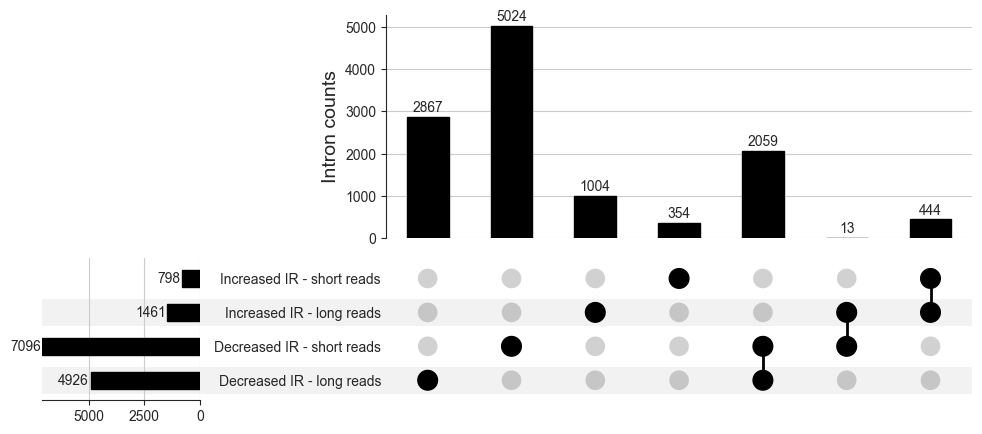

In [21]:
# overlaps short and long reads
shPABPN1_vs_shNT_nucleus_reduced = shPABPN1_vs_shNT_nucleus[['Chr', 'Start', 'End', 'Strand', 'gene_name', 'intron_order', 'dir']].drop_duplicates()
shPABPN1_vs_shNT_nucleus_reduced.columns = ['chrom', 'intron_start', 'intron_end', 'strand', 'gene_name', 'intron_order', 'dir_short']
nucleus_merge_long_short = nucleus_introns.merge(shPABPN1_vs_shNT_nucleus_reduced, on = ['chrom', 'intron_start', 'intron_end', 'strand', 'gene_name', 'intron_order'], how = 'outer')
nucleus_merge_long_short[['dir', 'dir_short']] = nucleus_merge_long_short[['dir', 'dir_short']].fillna('not_significant')
nucleus_merge_long_short_count = nucleus_merge_long_short.groupby(by = ['dir', 'dir_short'])['intron_start'].count().reset_index()

nucleus_merge_long_short = nucleus_merge_long_short.reset_index()
nucleus_merge_long_short_upset = nucleus_merge_long_short[['index']]

list_indexes_less_IR_long = nucleus_merge_long_short[nucleus_merge_long_short['dir'] == 'less_IR_PABPN1']['index'].tolist()
list_indexes_less_IR_short = nucleus_merge_long_short[nucleus_merge_long_short['dir_short'] == 'less_IR_PABPN1']['index'].tolist()
list_indexes_more_IR_long = nucleus_merge_long_short[nucleus_merge_long_short['dir'] == 'more_IR_PABPN1']['index'].tolist()
list_indexes_more_IR_short = nucleus_merge_long_short[nucleus_merge_long_short['dir_short'] == 'more_IR_PABPN1']['index'].tolist()


nucleus_merge_long_short_upset['Decreased IR - long reads'] = False
nucleus_merge_long_short_upset['Decreased IR - short reads'] = False
nucleus_merge_long_short_upset['Increased IR - long reads'] = False
nucleus_merge_long_short_upset['Increased IR - short reads'] = False
nucleus_merge_long_short_upset.loc[nucleus_merge_long_short_upset['index'].isin(list_indexes_less_IR_long), 'Decreased IR - long reads'] = True
nucleus_merge_long_short_upset.loc[nucleus_merge_long_short_upset['index'].isin(list_indexes_less_IR_short), 'Decreased IR - short reads'] = True
nucleus_merge_long_short_upset.loc[nucleus_merge_long_short_upset['index'].isin(list_indexes_more_IR_long), 'Increased IR - long reads'] = True
nucleus_merge_long_short_upset.loc[nucleus_merge_long_short_upset['index'].isin(list_indexes_more_IR_short), 'Increased IR - short reads'] = True
nucleus_merge_long_short_upset = nucleus_merge_long_short_upset[(nucleus_merge_long_short_upset['Decreased IR - long reads'] != False) |
                                                            (nucleus_merge_long_short_upset['Decreased IR - short reads'] != False) |
                                                            (nucleus_merge_long_short_upset['Increased IR - long reads'] != False) |
                                                            (nucleus_merge_long_short_upset['Increased IR - short reads'] != False)]
nucleus_merge_long_short_upset = nucleus_merge_long_short_upset.groupby(by = ['Decreased IR - long reads', 'Decreased IR - short reads', 'Increased IR - long reads', 'Increased IR - short reads'])['index'].count()

fig = plt.figure(figsize=(12, 5))
upset.plot(nucleus_merge_long_short_upset, show_counts=True, fig = fig, element_size=None, sort_categories_by = 'input')
plt.title('')
plt.ylabel('Intron counts', fontsize = 14)
plt.show()


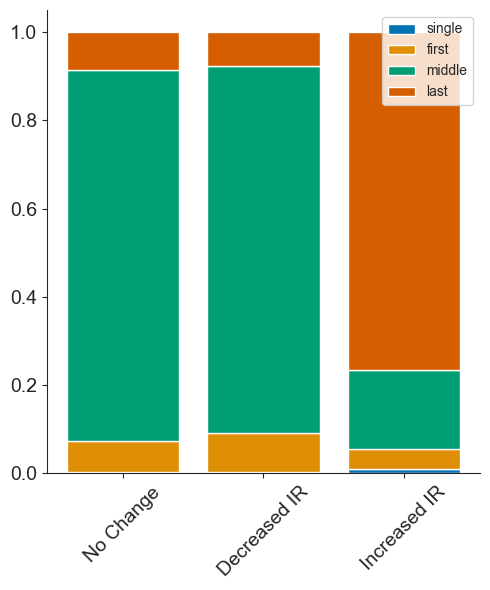

In [22]:
# barplot intron proportions Nucleus
shPABPN1_vs_shNT_nucleus_count = shPABPN1_vs_shNT_nucleus.groupby(by = ['dir', 'intron_order'])['Name'].count().reset_index().rename(columns={'Name' : 'intron_count'})
shPABPN1_vs_shNT_nucleus_count['proportion'] = shPABPN1_vs_shNT_nucleus_count.apply(lambda row : prop_intron_position(row.dir, row.intron_count, shPABPN1_vs_shNT_nucleus_count), axis = 1)

shPABPN1_vs_shNT_nucleus_count_piv = shPABPN1_vs_shNT_nucleus_count.pivot_table(index = 'dir', columns = 'intron_order', values = 'proportion')
shPABPN1_vs_shNT_nucleus_count_piv = shPABPN1_vs_shNT_nucleus_count_piv[['single', 'first', 'middle', 'last']]
shPABPN1_vs_shNT_nucleus_count_piv = shPABPN1_vs_shNT_nucleus_count_piv.loc[['not_significant', 'less_IR_PABPN1', 'more_IR_PABPN1']]
shPABPN1_vs_shNT_nucleus_count_piv.index = ['No Change', 'Decreased IR', 'Increased IR']

fig, ax = plt.subplots(figsize=(5,6))
left = np.zeros(len(shPABPN1_vs_shNT_nucleus_count_piv))
palette = sns.color_palette('colorblind', n_colors=shPABPN1_vs_shNT_nucleus_count_piv.shape[1])
for i, col in enumerate(shPABPN1_vs_shNT_nucleus_count_piv.columns):
    ax.bar(shPABPN1_vs_shNT_nucleus_count_piv.index, shPABPN1_vs_shNT_nucleus_count_piv[col], bottom=left, label=col, color=palette[i])
    left += shPABPN1_vs_shNT_nucleus_count_piv[col].values
#ax.set_ylim(0, 1)
#plt.title('Nucleus', fontsize = 18)
ax.tick_params(labelsize=14)
ax.set_ylabel('')
ax.set_xlabel('')
ax.set_xticks([0,1,2], shPABPN1_vs_shNT_nucleus_count_piv.index, rotation= 45)
sns.despine()
ax.legend()
plt.tight_layout()


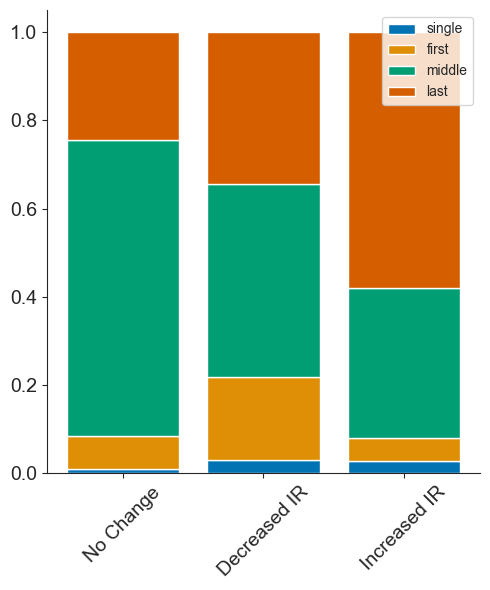

In [23]:
# barplot intron proportions cyto
shPABPN1_vs_shNT_cyto_count = shPABPN1_vs_shNT_cyto.groupby(by = ['dir', 'intron_order'])['Name'].count().reset_index().rename(columns={'Name' : 'intron_count'})
shPABPN1_vs_shNT_cyto_count['proportion'] = shPABPN1_vs_shNT_cyto_count.apply(lambda row : prop_intron_position(row.dir, row.intron_count, shPABPN1_vs_shNT_cyto_count), axis = 1)

shPABPN1_vs_shNT_cyto_count_piv = shPABPN1_vs_shNT_cyto_count.pivot_table(index = 'dir', columns = 'intron_order', values = 'proportion')
shPABPN1_vs_shNT_cyto_count_piv = shPABPN1_vs_shNT_cyto_count_piv[['single', 'first', 'middle', 'last']]
shPABPN1_vs_shNT_cyto_count_piv = shPABPN1_vs_shNT_cyto_count_piv.loc[['not_significant', 'less_IR_PABPN1', 'more_IR_PABPN1']]
shPABPN1_vs_shNT_cyto_count_piv.index = ['No Change', 'Decreased IR', 'Increased IR']

fig, ax = plt.subplots(figsize=(5,6))
left = np.zeros(len(shPABPN1_vs_shNT_cyto_count_piv))
palette = sns.color_palette('colorblind', n_colors=shPABPN1_vs_shNT_cyto_count_piv.shape[1])
for i, col in enumerate(shPABPN1_vs_shNT_cyto_count_piv.columns):
    ax.bar(shPABPN1_vs_shNT_cyto_count_piv.index, shPABPN1_vs_shNT_cyto_count_piv[col], bottom=left, label=col, color=palette[i])
    left += shPABPN1_vs_shNT_cyto_count_piv[col].values
#ax.set_ylim(0, 1)
#plt.title('cyto', fontsize = 18)
ax.tick_params(labelsize=14)
ax.set_ylabel('')
ax.set_xlabel('')
ax.set_xticks([0,1,2], shPABPN1_vs_shNT_cyto_count_piv.index, rotation= 45)
sns.despine()
ax.legend()
plt.tight_layout()